# 07 — AdaBoost

**Algorithm:** Adaptive Boosting (AdaBoost)  
**Features:** TF-IDF (50K unigrams + bigrams)  
AdaBoost sequentially trains weak learners (decision stumps), re-weighting misclassified samples. The staged nature makes convergence analysis particularly informative.

In [1]:
import os, sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), '..')))
from utils import (setup_paths, evaluate_and_print, plot_confusion_matrix,
                   plot_roc_curve, plot_pr_curve, plot_learning_curve)
from sklearn.metrics import accuracy_score
BASE_DIR, FIGURES_DIR = setup_paths()

In [2]:
from preprocess import load_all_datasets, get_train_test_split
df = load_all_datasets()
X_train, X_test, y_train, y_test = get_train_test_split(df)
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(max_features=50000, ngram_range=(1,2), sublinear_tf=True, min_df=2, max_df=0.95)
X_tr = tfidf.fit_transform(X_train)
X_te = tfidf.transform(X_test)
print(f'Train: {len(X_train):,}  |  Test: {len(X_test):,}')


  LOADING ALL DATASETS
  [1/5] Loading ISOT Dataset...
      Loaded 44,898 records  (Fake=23,481  Real=21,417)
  [2/5] Loading FakeNewsNet Dataset...
      Loaded 23,196 records  (Fake=5,755  Real=17,441)
  [3/5] Loading LIAR Dataset...
      Loaded 12,791 records  (Fake=5,657  Real=7,134)
  [4/5] Loading MultiFC Dataset...
      Loaded 31,921 records  (Fake=13,980  Real=17,941)
  [5/5] Loading BuzzFeed Dataset...
      Loaded 2,282 records  (Fake=613  Real=1,669)

  Combined total   : 115,088 records
  Fake (0)         : 49,486
  Real (1)         : 65,602

  Cleaning text...
  After clean+dedup: 104,521 records

  Source distribution:
source
ISOT           38826
MultiFC        31919
FakeNewsNet    21046
LIAR           12726
BuzzFeed           4
Train: 83,616  |  Test: 20,905


## Model Training

In [3]:
from sklearn.ensemble import AdaBoostClassifier
MODEL_NAME = 'AdaBoost'
model = AdaBoostClassifier(n_estimators=100, random_state=42, algorithm='SAMME')
t0 = time.time()
model.fit(X_tr, y_train)
train_time = time.time() - t0
print(f'Training completed in {train_time:.2f}s')

Training completed in 531.15s


In [4]:
metrics, y_pred, y_prob = evaluate_and_print(model, X_te, y_test, MODEL_NAME, train_time)


  AdaBoost — Evaluation Results
  Accuracy          : 0.7758
  Precision         : 0.7855
  Recall            : 0.7758
  F1 Score          : 0.7658
  AUC-ROC           : 0.8514
  Train Time (s)    : 531.15s

              precision    recall  f1-score   support

    Fake (0)       0.83      0.57      0.67      8532
    Real (1)       0.76      0.92      0.83     12373

    accuracy                           0.78     20905
   macro avg       0.79      0.74      0.75     20905
weighted avg       0.79      0.78      0.77     20905



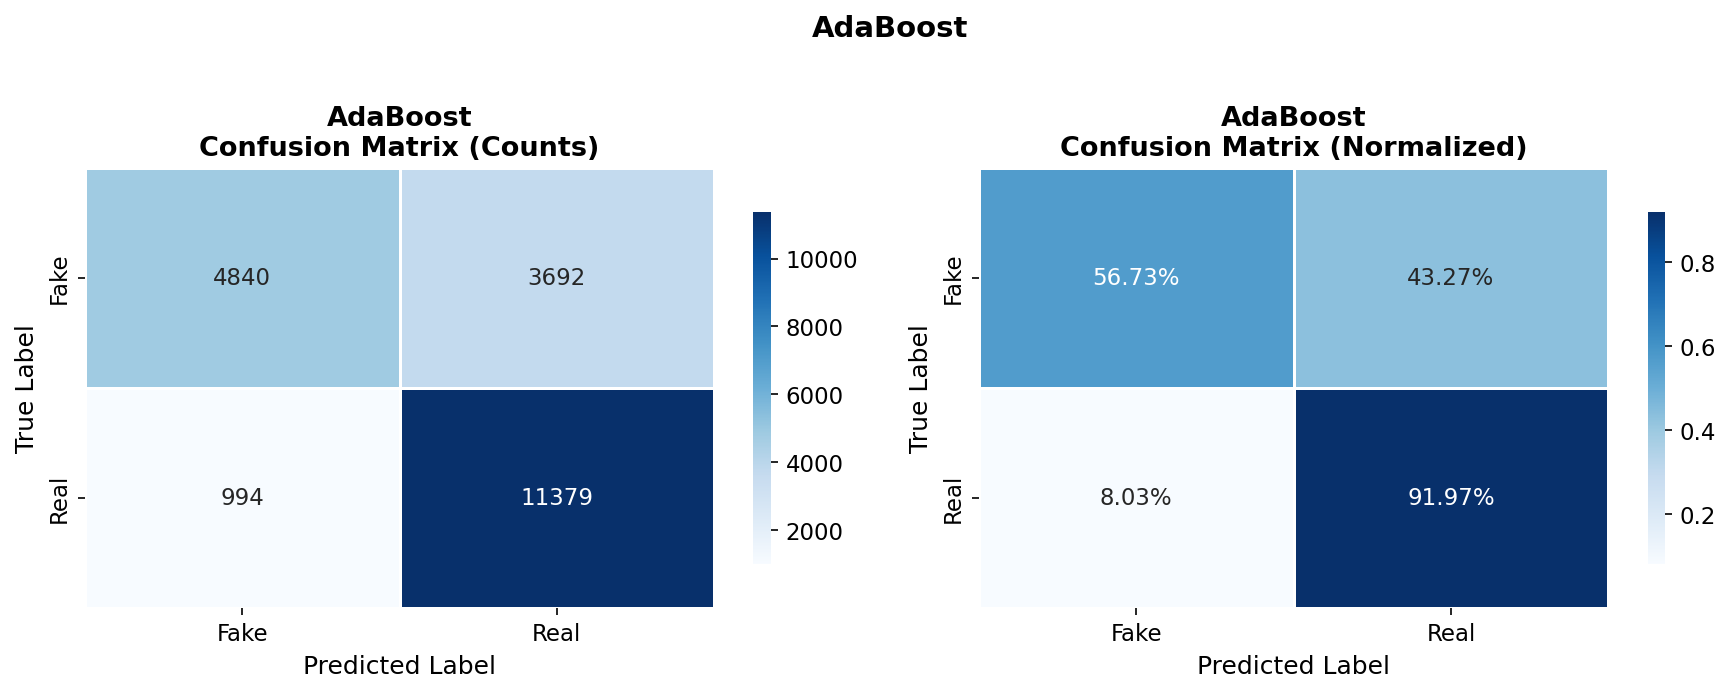

In [5]:
plot_confusion_matrix(y_test, y_pred, MODEL_NAME, FIGURES_DIR)

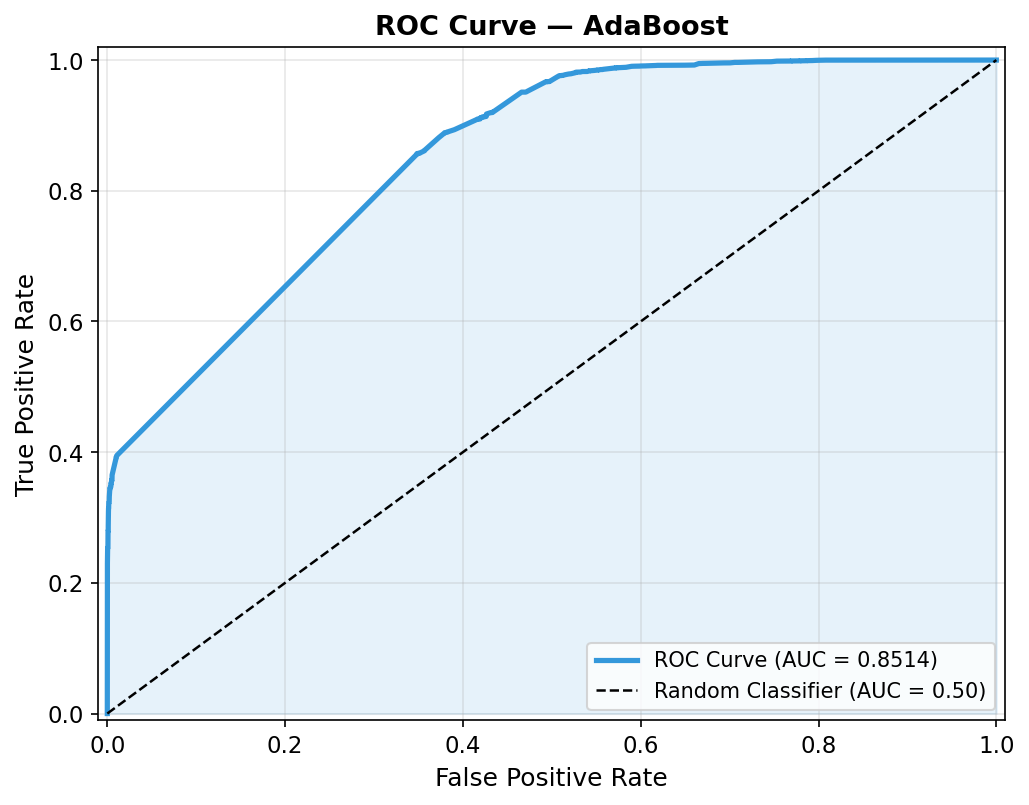

In [6]:
plot_roc_curve(y_test, y_prob, MODEL_NAME, FIGURES_DIR)

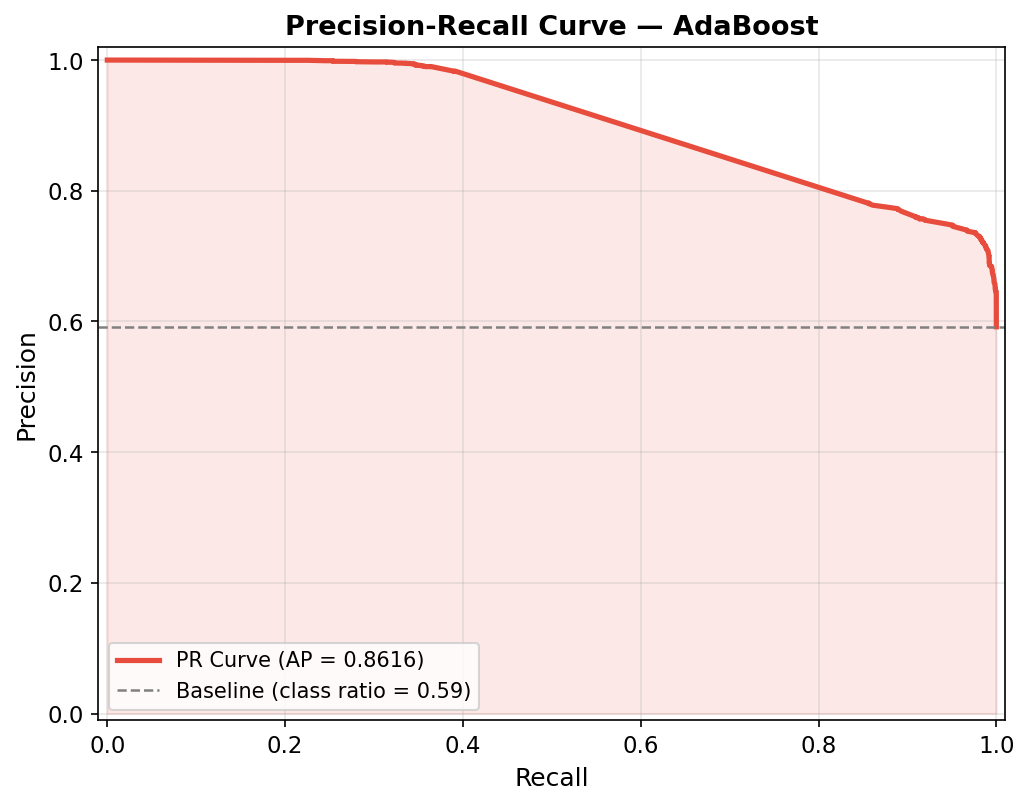

In [7]:
plot_pr_curve(y_test, y_prob, MODEL_NAME, FIGURES_DIR)

## Training Convergence: Staged Accuracy per Round

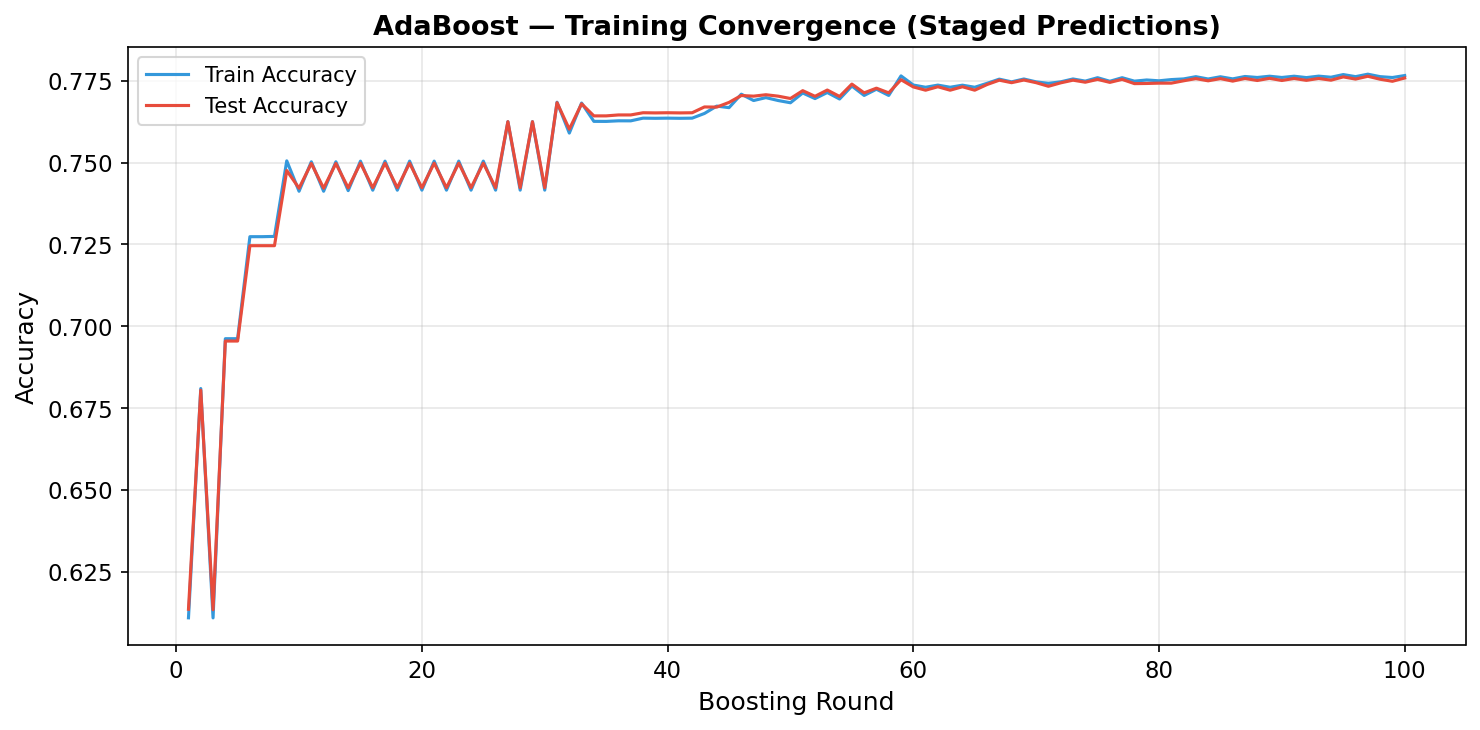

Peak test accuracy at round 97: 0.7764


In [8]:
staged_tr = [accuracy_score(y_train, p) for p in model.staged_predict(X_tr)]
staged_te = [accuracy_score(y_test,  p) for p in model.staged_predict(X_te)]
rounds = list(range(1, len(staged_tr) + 1))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(rounds, staged_tr, color='#3498db', lw=1.5, label='Train Accuracy')
ax.plot(rounds, staged_te, color='#e74c3c', lw=1.5, label='Test Accuracy')
ax.set_xlabel('Boosting Round')
ax.set_ylabel('Accuracy')
ax.set_title('AdaBoost — Training Convergence (Staged Predictions)')
ax.legend(fontsize=10); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'adaboost_convergence.png'), dpi=150, bbox_inches='tight')
plt.show()
print(f'Peak test accuracy at round {np.argmax(staged_te)+1}: {max(staged_te):.4f}')

## Estimator Weights (Importance of Each Weak Learner)

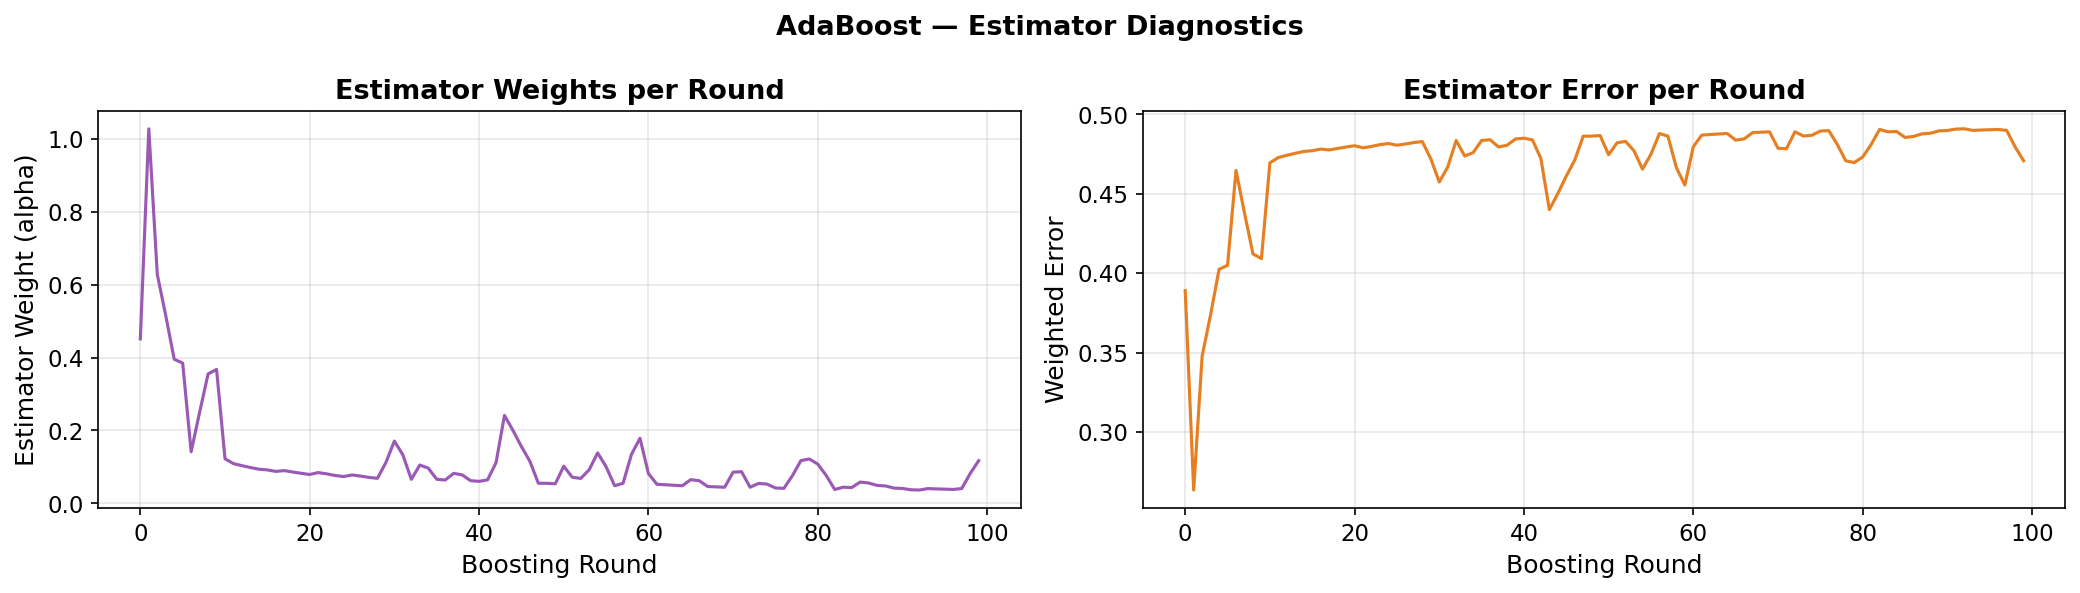

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(model.estimator_weights_, color='#9b59b6', lw=1.5)
axes[0].set_xlabel('Boosting Round')
axes[0].set_ylabel('Estimator Weight (alpha)')
axes[0].set_title('Estimator Weights per Round')
axes[0].grid(alpha=0.3)

axes[1].plot(model.estimator_errors_, color='#e67e22', lw=1.5)
axes[1].set_xlabel('Boosting Round')
axes[1].set_ylabel('Weighted Error')
axes[1].set_title('Estimator Error per Round')
axes[1].grid(alpha=0.3)

plt.suptitle('AdaBoost — Estimator Diagnostics', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'adaboost_estimator_diagnostics.png'), dpi=150, bbox_inches='tight')
plt.show()

## Learning Curve

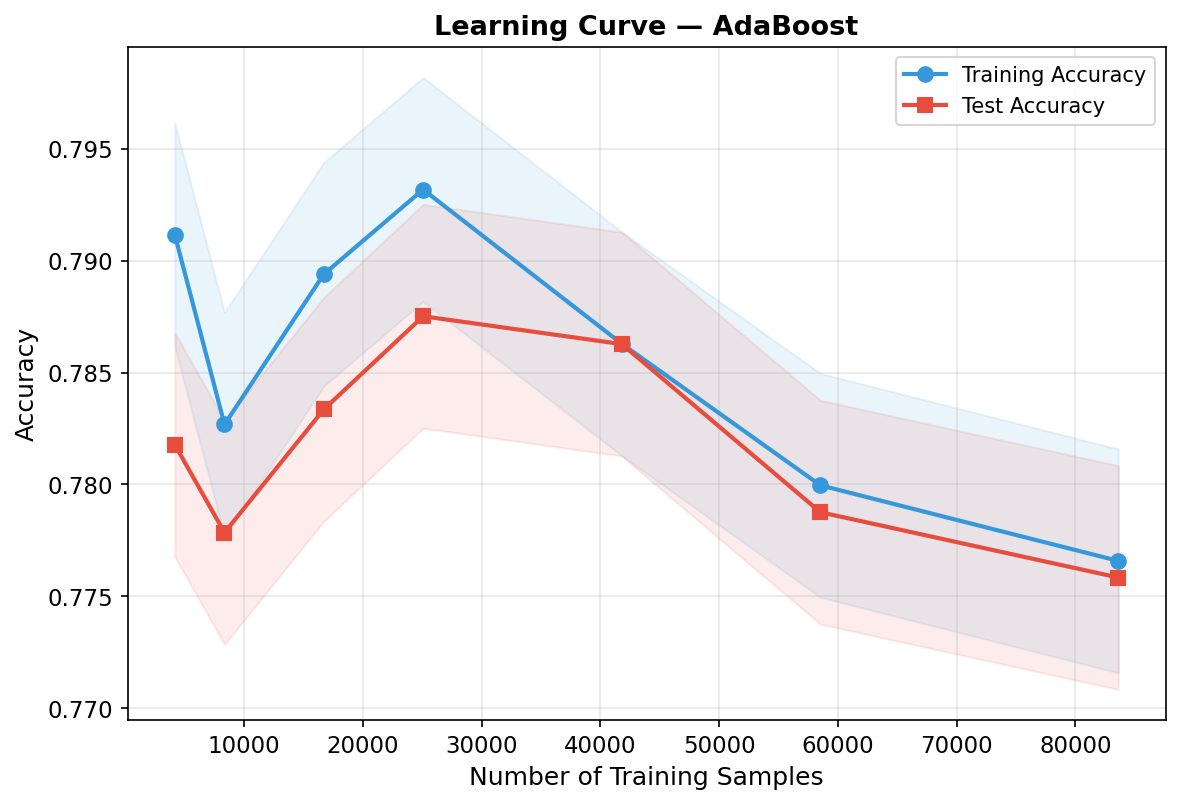

([4180, 8361, 16723, 25084, 41808, 58531, 83616],
 [0.7911483253588517,
  0.7826814974285372,
  0.7893918555283143,
  0.7931749322277148,
  0.7862849215461156,
  0.7799627547795186,
  0.7765858208955224],
 [0.7817746950490313,
  0.7778521884716575,
  0.783353264769194,
  0.7875149485768955,
  0.7862712269791916,
  0.7787610619469026,
  0.775843099736905])

In [10]:
plot_learning_curve(model, X_tr, y_train, X_te, y_test, MODEL_NAME, FIGURES_DIR)